# Lab 6: Logistic Regression & KNN Classification Telco Customer Churn

**Name:** Yusra Batool

**Student ID:** 023-24-0216

**Section:** G

**GitHub Profile:** github.com/Yusra-Shah

**Kaggle Profile:** https://www.kaggle.com/yusrabatool

**Dataset:** Telco Customer Churn (Kaggle)

## Part 1 : Problem Definition & Dataset Verification

In [33]:
# Task 1 reload and verify clean_churn.csv
import pandas as pd
import numpy as np

clean_df = pd.read_csv("clean_churn.csv")
print(clean_df.shape)
print(clean_df.dtypes)
print(clean_df.isnull().sum().sum())

(7043, 20)
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object
0


**Task 2 Lab 3/4 benchmark recap:** The Lab 3 Decision Tree (max_depth=6) scored accuracy 0.8006, precision 0.6667, recall 0.4973, F1 0.5697 on the test set. The Lab 4 tuned Random Forest scored accuracy 0.7970, precision 0.6507, recall 0.5080, F1 0.5706, marginally better F1 than the tree but slightly lower accuracy. These two numbers are today's benchmark, anything new needs to beat, or at least meaningfully differ from, an F1 around 0.57.

## Part 2 : Feature Scaling & Preparation

In [34]:
# Task 3 prepare X and y (same as Lab 3/4)
from sklearn.model_selection import train_test_split

y = clean_df["Churn"].map({"No": 0, "Yes": 1})
X = clean_df.drop(columns=["Churn"])
categorical_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print(X.shape)

(7043, 30)


**Task 4 why scaling matters here but not before:** Decision Trees and Random Forests split one feature at a time based on threshold comparisons (is tenure > 12?), so the raw scale of each feature never affects how splits are chosen. KNN and Logistic Regression are different: KNN measures straight-line distance between data points, so a feature like MonthlyCharges (ranging roughly 20-120) would dominate the distance calculation entirely over something like tenure (ranging 0-72) purely because of its bigger numbers, not because it's actually more important. Logistic Regression doesn't strictly require scaling to function, but its coefficients become far easier to compare fairly across features once every feature is on the same scale, and its optimizer also converges faster and more reliably.

In [35]:
# Task 5 train/test split, fit scaler on training data only
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (5634, 30) X_test: (1409, 30)


**Why fit the scaler on training data only:** If we fit the scaler on the full dataset before splitting, information from the test set (its mean and spread) would leak into how the training data gets scaled, effectively letting the model "see" characteristics of data it's supposed to be evaluated on later. Fitting only on X_train and then using that same fitted scaler to transform X_test keeps the test set genuinely unseen, exactly the same leakage principle from Lab 3's train/test split discussion, just applied to preprocessing instead of the model itself.

## Part 3 : Logistic Regression

{'Accuracy': 0.8069552874378992, 'Precision': 0.6583850931677019, 'Recall': 0.5668449197860963, 'F1': 0.6091954022988506}


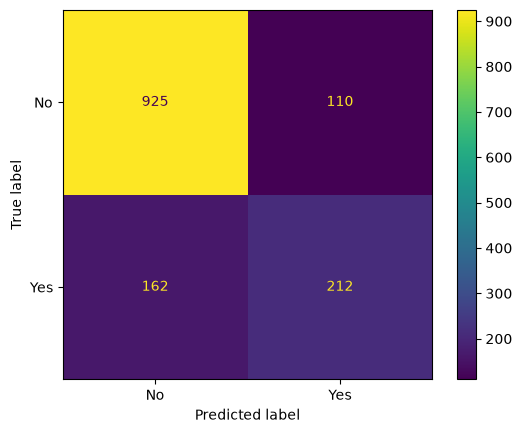

In [36]:
# Task 6-7  train Logistic Regression, evaluate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train_scaled, y_train)
logreg_preds = logreg.predict(X_test_scaled)

logreg_metrics = {
    "Accuracy": accuracy_score(y_test, logreg_preds),
    "Precision": precision_score(y_test, logreg_preds),
    "Recall": recall_score(y_test, logreg_preds),
    "F1": f1_score(y_test, logreg_preds),
}
print(logreg_metrics)

cm_logreg = confusion_matrix(y_test, logreg_preds)
ConfusionMatrixDisplay(cm_logreg, display_labels=["No", "Yes"]).plot()

**Evaluation note:** This already beats both Lab 3's Decision Tree (F1 0.5697) and Lab 4's tuned Random Forest (F1 0.5706) on every metric except precision, notably on recall (0.5668 vs 0.4973 and 0.5080), meaning it catches more actual churners than either tree-based model did.

In [37]:
# Task 8 predict_proba on a few test customers
probs = logreg.predict_proba(X_test_scaled)
print("P(No), P(Yes) for first 5 test customers:")
print(probs[:5].round(4))
print("Predictions:", logreg_preds[:5])

P(No), P(Yes) for first 5 test customers:
[[0.955  0.045 ]
 [0.3168 0.6832]
 [0.9435 0.0565]
 [0.5922 0.4078]
 [0.9783 0.0217]]
Predictions: [0 1 0 0 0]


**What predict_proba represents:** Each row gives the model's estimated probability that a customer belongs to each class, P(No) and P(Yes), and the two always sum to 1. predict() turns this into a Yes/No decision using a 0.5 threshold by default, whichever probability is higher wins, so customer 2 (P(Yes)=0.6832) gets predicted Yes, while customer 4 (P(Yes)=0.4078) still gets predicted No even though it's a fairly close call, just under the 0.5 line.

## Part 4 : KNN & Choosing K

In [38]:
# Task 9 test multiple K values
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
knn_results = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    knn_results.append({
        "K": k,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "F1": round(f1_score(y_test, preds), 4)
    })

knn_results_df = pd.DataFrame(knn_results)
print(knn_results_df)

    K  Accuracy      F1
0   1    0.7161  0.4764
1   3    0.7438  0.5128
2   5    0.7473  0.5123
3   7    0.7594  0.5324
4   9    0.7693  0.5578
5  11    0.7729  0.5616
6  15    0.7700  0.5537
7  21    0.7708  0.5617


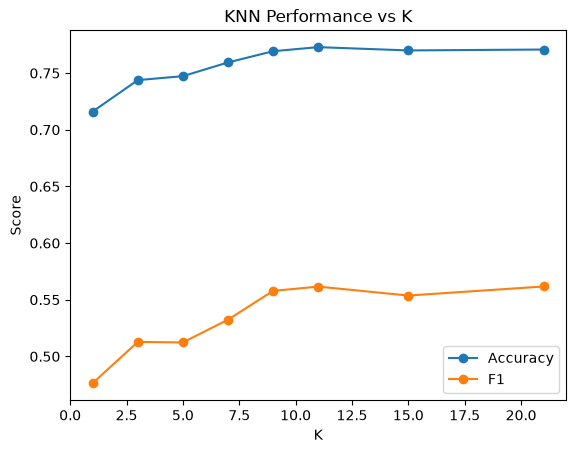

In [39]:
# Task 10 plot accuracy and F1 against K
import matplotlib.pyplot as plt

plt.plot(knn_results_df["K"], knn_results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(knn_results_df["K"], knn_results_df["F1"], marker="o", label="F1")
plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance vs K")
plt.legend()
plt.show()

**Task 10 choosing K:** I chose K=11. Both accuracy and F1 rise steadily from K=1 through K=11, then flatten out, K=15 actually dips slightly before K=21 recovers to almost the same F1 as K=11 (0.5617 vs 0.5616), a negligible difference. K=1 is the classic overfitting case, it's swayed by whichever single nearest point happens to be closest, including noisy outliers, giving the worst accuracy and F1 of anything tested. K=21 isn't meaningfully better than K=11 despite averaging over twice as many neighbors, so there's no benefit to going that high, it just costs more computation for the same result. K=11 sits right where the curve levels off, the smallest K that captures the plateau, not simply the smallest or largest value tried.

In [40]:
# Task 11 final KNN model at K=11
best_knn = KNeighborsClassifier(n_neighbors=11)
best_knn.fit(X_train_scaled, y_train)
knn_preds = best_knn.predict(X_test_scaled)

knn_metrics = {
    "Accuracy": accuracy_score(y_test, knn_preds),
    "Precision": precision_score(y_test, knn_preds),
    "Recall": recall_score(y_test, knn_preds),
    "F1": f1_score(y_test, knn_preds),
}
print(knn_metrics)
print(confusion_matrix(y_test, knn_preds))

{'Accuracy': 0.772888573456352, 'Precision': 0.5758426966292135, 'Recall': 0.5481283422459893, 'F1': 0.5616438356164384}
[[884 151]
 [169 205]]


## Part 5 : Model Comparison (4 Models)

In [41]:
# Task 12 full 4-model comparison table
dt_metrics = {"Accuracy": 0.8006, "Precision": 0.6667, "Recall": 0.4973, "F1": 0.5697}
rf_metrics = {"Accuracy": 0.7970, "Precision": 0.6507, "Recall": 0.5080, "F1": 0.5706}

comparison = pd.DataFrame({
    "Decision Tree": dt_metrics,
    "Random Forest": rf_metrics,
    "Logistic Regression": logreg_metrics,
    "KNN (K=11)": knn_metrics
})
print(comparison.round(4))

           Decision Tree  Random Forest  Logistic Regression  KNN (K=11)
Accuracy          0.8006         0.7970               0.8070      0.7729
Precision         0.6667         0.6507               0.6584      0.5758
Recall            0.4973         0.5080               0.5668      0.5481
F1                0.5697         0.5706               0.6092      0.5616


**Task 13 best model and ranking:** Logistic Regression wins overall, it has the highest accuracy (0.8070), highest recall (0.5668), and highest F1 (0.6092) of all four models. The ranking does shift by metric though, Decision Tree actually has the best precision (0.6667), meaning when it predicts "Yes" it's right slightly more often, but it misses far more actual churners than Logistic Regression does.KNN has the lowest accuracy, precision and F1 of the four models. Its recall (0.5481) is higher than the Decision Tree (0.4973) and Random Forest (0.5080), but its low precision (0.5758) means about 42% of its churn predictions are false alarms. Given the class imbalance found back in Lab 2, recall should carry the most weight, catching actual churners matters more than being cautious about false alarms, and Logistic Regression's clear recall advantage (0.5668 vs 0.4973-0.5481 for the others) makes it the strongest choice by that priority.

## Part 6 : Coefficient Interpretation

In [42]:
# Task 14 coefficients and odds ratios
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logreg.coef_[0]
})
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])
coef_df = coef_df.sort_values("Coefficient", ascending=False)
print("Intercept:", logreg.intercept_[0])
print(coef_df.to_string(index=False))

Intercept: -1.7045377902866787
                              Feature  Coefficient  Odds Ratio
          InternetService_Fiber optic     0.776154    2.173099
                         TotalCharges     0.514285    1.672442
                  StreamingMovies_Yes     0.257227    1.293338
                      StreamingTV_Yes     0.257144    1.293231
                    MultipleLines_Yes     0.216167    1.241310
                 PaperlessBilling_Yes     0.182034    1.199655
       PaymentMethod_Electronic check     0.181103    1.198539
                        SeniorCitizen     0.053073    1.054507
                 DeviceProtection_Yes     0.053048    1.054480
           PaymentMethod_Mailed check     0.032262    1.032788
                          gender_Male     0.011094    1.011156
                          Partner_Yes     0.010866    1.010926
                     PhoneService_Yes     0.006794    1.006817
       MultipleLines_No phone service    -0.006794    0.993229
                     Onl

In [43]:
notes = {
    "tenure": "One standard deviation more tenure multiplies the odds of churn by about 0.29 (about 71% lower).",
    "InternetService_Fiber optic": "Fiber optic customers have about 2.17 times the odds of churning compared with DSL customers.",
    "Contract_Two year": "Two year contract customers have about 0.56 times the odds of churning compared with month to month (about 44% lower).",
    "Contract_One year": "One year contract customers have about 0.75 times the odds of churning compared with month to month (about 25% lower).",
    "TotalCharges": "One standard deviation more TotalCharges multiplies the odds of churn by about 1.67, holding other features constant.",
}
coef_df["Interpretation"] = coef_df["Feature"].map(notes).fillna("")
print(coef_df[coef_df["Interpretation"] != ""].to_string(index=False))

                    Feature  Coefficient  Odds Ratio                                                                                                         Interpretation
InternetService_Fiber optic     0.776154    2.173099                          Fiber optic customers have about 2.17 times the odds of churning compared with DSL customers.
               TotalCharges     0.514285    1.672442  One standard deviation more TotalCharges multiplies the odds of churn by about 1.67, holding other features constant.
          Contract_One year    -0.285509    0.751632 One year contract customers have about 0.75 times the odds of churning compared with month to month (about 25% lower).
          Contract_Two year    -0.586859    0.556071 Two year contract customers have about 0.56 times the odds of churning compared with month to month (about 44% lower).
                     tenure    -1.236528    0.290391                       One standard deviation more tenure multiplies the odds of churn b

Reading the table: tenure, MonthlyCharges and TotalCharges were scaled, so their odds ratios are per one standard deviation, not per month or per dollar. An odds ratio below 1 lowers the odds of churn and above 1 raises them. The seven "No internet service" columns share the same coefficient (-0.0928) because they are identical columns.

Note on interpreting MonthlyCharges: Its negative coefficient should not be read as "higher bills reduce churn". TotalCharges is roughly tenure times MonthlyCharges, and MonthlyCharges is also driven by services like fiber and streaming, which have their own coefficients. Because these features overlap, the model splits their effects in ways that can flip a sign. This is why coefficients need "holding other features constant" attached, and why the sign here does not contradict the simple boxplot from Lab 2.

**Task 15 agreement with earlier labs:** tenure and InternetService_Fiber optic both showing up as top effects here directly matches Lab 3's Decision Tree, where tenure was the single most important feature and fiber optic internet was the second most important. Contract_Two year reducing churn odds also matches Lab 2's EDA, where two-year contracts had the lowest churn rate (about 3%) of any contract type. The one disagreement is MonthlyCharges, which showed higher churn at higher bills in Lab 2's simple boxplot, but shows a churn-reducing coefficient here once tenure and TotalCharges are controlled for simultaneously, a case where multivariate analysis tells a more nuanced story than a single-variable chart could.

## Part 7 : Final Model Selection & Conclusion

**Task 16 final model selection:** I'm selecting Logistic Regression as the final model. It leads the Part 5 comparison table on three of four metrics, accuracy, recall, and F1, and its recall advantage in particular matters most given the churn class imbalance. That said, Lab 4's cross-validation lesson is a real caution here, this is one single train/test split, and Lab 4 showed that single-split rankings can flip under cross-validation (the Decision Tree actually beat the default Random Forest on 5-fold F1 despite losing on the single split). So while Logistic Regression is my pick based on today's evidence, I'd want to confirm this with cross-validation before treating it as a settled conclusion rather than a single-split result.

**Task 17 conclusion:** Logistic Regression came out ahead of both Lab 3's Decision Tree and Lab 4's Random Forest today, improving F1 from about 0.57 to 0.6092, mainly by catching noticeably more actual churners (recall 0.5668 vs 0.4973-0.5080). Feature scaling was the biggest procedural change this lab introduced, without it, KNN's distance calculations would have been dominated by whichever feature happened to have the largest raw numeric range, and Logistic Regression's coefficients wouldn't have been directly comparable across features the way the odds-ratio table above is. KNN ended up the weakest on accuracy, precision and F1, even after tuning K, suggesting this dataset's churn signal isn't well captured by simple neighbor-distance in the encoded feature space. The main limitation of Logistic Regression here is that it assumes a linear relationship between each feature and the log-odds of churning, it can't capture interaction effects the way a tree-based model naturally can, and its recall, while the best of the four, still misses over 40% of actual churners. With more time, I'd try combining Logistic Regression's interpretability with Lab 4's cross-validation approach to confirm today's ranking holds up, and would experiment with adjusting the classification threshold below 0.5 to trade some precision for even better recall, since recall is what matters most for this business problem.